###                                            === Khái báo các thư viện cần thiết ===

In [30]:
import torch
import torch.nn                  as nn
import torch.optim               as optim
import torch.nn.functional       as F
from torch.utils.data            import WeightedRandomSampler

# Torchvision for dataset loading, transforms, and pre-trained models
import torchvision.transforms    as transforms
from torchvision.datasets        import ImageFolder
from torchvision                 import datasets
from torchvision.utils           import make_grid

# DataLoader utilities
from torch.utils.data            import random_split, Subset
from torch.utils.data.dataloader import DataLoader

# Visualization and utilities
import matplotlib.pyplot         as plt
import numpy                     as np
import os
from typing                      import Literal
from sklearn.metrics             import confusion_matrix, classification_report
from sklearn.model_selection     import train_test_split
import seaborn                   as sns

from collections                 import Counter
from tabulate                    import tabulate

%matplotlib inline

### === Kiểm tra bộ dữ liệu trước khi huấn luyện ===

In [31]:
root_dir = "garbage_classification"
rows = []
total_images = 0

for root, dirs, files in os.walk(root_dir):
    images = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if len(images) > 0:
        rows.append([os.path.basename(root), f"{len(images):,}"])
        total_images += len(images)

rows.append(["TỔNG CỘNG", f"{total_images:,}"])

print(tabulate(rows, headers=["Thư mục", "Số ảnh"], tablefmt="rounded_outline"))

╭────────────────────┬──────────╮
│ Thư mục            │   Số ảnh │
├────────────────────┼──────────┤
│ clothes            │    5,325 │
│ paper              │    1,644 │
│ shoes              │    1,977 │
│ plastic            │    1,347 │
│ battery            │      945 │
│ .ipynb_checkpoints │        1 │
│ metal              │    1,179 │
│ biological         │      984 │
│ trash              │      834 │
│ cardboard          │    1,294 │
│ green-glass        │      684 │
│ white-glass        │      984 │
│ brown-glass        │      671 │
│ TỔNG CỘNG          │   17,869 │
╰────────────────────┴──────────╯


In [32]:
classes = sorted([
    d for d in os.listdir(root_dir)
    if os.path.isdir(os.path.join(root_dir, d))
    and not d.startswith(".")
    and not d.startswith("__")
])

num_classes = len(classes)

print(tabulate(
    [[i, cls] for i, cls in enumerate(classes)],
    headers=["Index", "Class"],
    tablefmt="rounded_outline",
    showindex=False
))
print(f"Tổng: {num_classes} lớp")

╭─────────┬─────────────╮
│   Index │ Class       │
├─────────┼─────────────┤
│       0 │ battery     │
│       1 │ biological  │
│       2 │ brown-glass │
│       3 │ cardboard   │
│       4 │ clothes     │
│       5 │ green-glass │
│       6 │ metal       │
│       7 │ paper       │
│       8 │ plastic     │
│       9 │ shoes       │
│      10 │ trash       │
│      11 │ white-glass │
╰─────────┴─────────────╯
Tổng: 12 lớp


### === DATA PREPARATION ===

In [33]:
# 0. ĐỊNH NGHĨA CleanImageFolder
class CleanImageFolder(ImageFolder):
    def find_classes(self, directory):
        classes      = sorted([
            d for d in os.listdir(directory)
            if os.path.isdir(os.path.join(directory, d))
            and not d.startswith(".")
            and not d.startswith("__")
        ])
        class_to_idx = {cls: i for i, cls in enumerate(classes)}
        return classes, class_to_idx

# 1. TRANSFORMS
train_transform      = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),          
    transforms.RandomAffine(
        degrees      = 0,                          
        translate    = (0.05, 0.05),             
        scale        = (0.9, 1.1),                   
        shear        = 5                             
    ),
    transforms.ColorJitter(
        brightness   = 0.1,
        contrast     = 0.1,
        saturation   = 0.1,
        hue=0
    ),
    transforms.RandomAdjustSharpness(sharpness_factor = 2, p = 0.3),   # thêm giúp phân biệt texture nhựa/kính/kim loại

    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])

val_test_transform   = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize( [0.485, 0.456, 0.406],
                          [0.229, 0.224, 0.225]),
])

In [34]:
# LOAD DATASET
train_dataset        = CleanImageFolder(root=root_dir, transform=train_transform)
val_test_dataset     = CleanImageFolder(root=root_dir, transform=val_test_transform)

In [35]:
# CHIA INDICES
indices              = list(range(len(train_dataset)))

train_idx, temp_idx  = train_test_split(
    indices, test_size=0.30,
    stratify=train_dataset.targets, random_state=42
)

val_idx, test_idx    = train_test_split(
    temp_idx, test_size=0.50,
    stratify         = [train_dataset.targets[i] for i in temp_idx], random_state=42
)

In [36]:
# TẠO SUBSET
train_data           = Subset(train_dataset,    train_idx)
val_data             = Subset(val_test_dataset, val_idx)
test_data            = Subset(val_test_dataset, test_idx)

In [37]:
# CLASS WEIGHTS
targets              = train_dataset.targets
class_counts         = Counter(targets)
classes              = train_dataset.classes
counts               = [class_counts[i] for i in range(len(classes))]
total_samples        = sum(counts)
weights              = [total_samples / (len(classes) * c) for c in counts]

print(tabulate(
    [[cls, f"{w:.3f}"] for cls, w in zip(classes, weights)],
    headers          = ["Class", "Weight"],
    tablefmt         = "rounded_outline"
))
print (counts)

╭─────────────┬──────────╮
│ Class       │   Weight │
├─────────────┼──────────┤
│ battery     │    1.574 │
│ biological  │    1.513 │
│ brown-glass │    2.219 │
│ cardboard   │    1.151 │
│ clothes     │    0.28  │
│ green-glass │    2.177 │
│ metal       │    1.263 │
│ paper       │    0.906 │
│ plastic     │    1.105 │
│ shoes       │    0.753 │
│ trash       │    1.785 │
│ white-glass │    1.513 │
╰─────────────┴──────────╯
[946, 984, 671, 1294, 5325, 684, 1179, 1644, 1347, 1977, 834, 984]


In [38]:
# WEIGHTED SAMPLER cho train_loader
sample_weights       = [weights[t] for t in train_dataset.targets]

sampler              = WeightedRandomSampler(
    weights          = sample_weights,
    num_samples      = len(sample_weights),
    replacement      = True
)

In [39]:
# DATALOADERS
train_loader         = DataLoader(train_data, batch_size=32, sampler=sampler, num_workers=0)
val_loader           = DataLoader(val_data,   batch_size=32, shuffle=False,   num_workers=0)
test_loader          = DataLoader(test_data,  batch_size=32, shuffle=False,   num_workers=0)

# INFO
print(tabulate(
    [["Train", len(train_data)],
     ["Val",   len(val_data)],
     ["Test",  len(test_data)],
     ["Tổng",  len(train_dataset)]],
    headers          = ["Split", "Số ảnh"],
    tablefmt         = "rounded_outline"
))
print(tabulate(
    [[cls, Counter(train_dataset.targets)[i]] 
     for i, cls in enumerate(train_dataset.classes)],
    headers          = ["Class", "Số ảnh"],
    tablefmt         = "rounded_outline"
))

╭─────────┬──────────╮
│ Split   │   Số ảnh │
├─────────┼──────────┤
│ Train   │    12508 │
│ Val     │     2680 │
│ Test    │     2681 │
│ Tổng    │    17869 │
╰─────────┴──────────╯
╭─────────────┬──────────╮
│ Class       │   Số ảnh │
├─────────────┼──────────┤
│ battery     │      946 │
│ biological  │      984 │
│ brown-glass │      671 │
│ cardboard   │     1294 │
│ clothes     │     5325 │
│ green-glass │      684 │
│ metal       │     1179 │
│ paper       │     1644 │
│ plastic     │     1347 │
│ shoes       │     1977 │
│ trash       │      834 │
│ white-glass │      984 │
╰─────────────┴──────────╯


In [40]:
pip install tabulate

Note: you may need to restart the kernel to use updated packages.


### === CNN ===

In [41]:
class CNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            
            # Block 2
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            
            # Block 3
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            
            # Block 4
            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

### === MODEL ===

In [42]:
# DEVICE
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


In [43]:
# MODEL
model = CNN(num_classes=len(train_dataset.classes)).to(device)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights_loss  = [w ** 0.5 for w in weights]  
class_weights = torch.FloatTensor(weights_loss).to(device)

print("Class weights (đã làm dịu, dùng cho loss):")
for cls, w in zip(classes, weights_loss):
    print(f"  {cls:<15} {w:.3f}")

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)

Class weights (đã làm dịu, dùng cho loss):
  battery         1.255
  biological      1.230
  brown-glass     1.490
  cardboard       1.073
  clothes         0.529
  green-glass     1.475
  metal           1.124
  paper           0.952
  plastic         1.051
  shoes           0.868
  trash           1.336
  white-glass     1.230


In [44]:
# OPTIMIZER
optimizer        = torch.optim.Adam(
    model.parameters(),
    lr           = 0.001,
    weight_decay = 1e-4
)

In [45]:
total     = sum(p.numel() for p in model.parameters())
print(f"\nSố class   : {len(train_dataset.classes)}")
print(f"Classes    : {train_dataset.classes}")
print(f"Tổng params: {total:,}")

model.load_state_dict(torch.load(
    "/home/vulethanh/project/Machine Learning/best_model_v3_1.pth",
    map_location=device, weights_only=True
))
optimizer = torch.optim.Adam(model.parameters(), lr=0.00006, weight_decay=1e-4)


Số class   : 12
Classes    : ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Tổng params: 1,311,916


### === TRAIN LOOP ===

In [22]:
# ── Scheduler ─────────────────────────────────
scheduler                = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode                 = "max", 
    factor               = 0.5, 
    patience             = 3, 
    verbose              = False
)

epochs                   = 20
best_val_acc             = 0.8802
patience                 = 8
no_improve               = 0

train_acc_list           = []
train_loss_list          = []
val_acc_list             = []
val_loss_list            = []

for epoch in range(epochs):
    # ── TRAIN ─────────────────────────────────
    model.train()
    running_loss         = 0.0
    correct              = 0
    total                = 0

    for images, labels in train_loader:
        images           = images.to(device)          
        labels           = labels.to(device)
        optimizer.zero_grad()
        outputs          = model(images)
        loss             = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        running_loss    += loss.item()
        _, predicted     = torch.max(outputs, 1)
        correct         += (predicted == labels).sum().item()
        total           += labels.size(0)

    train_loss           = running_loss / len(train_loader)
    train_acc            = correct / total
    train_loss_list.append(train_loss)
    train_acc_list.append(train_acc)

    # ── VALIDATION ────────────────────────────
    model.eval()
    val_loss             = 0.0
    val_correct          = 0
    val_total            = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images       = images.to(device)
            labels       = labels.to(device)
            outputs      = model(images)
            loss         = criterion(outputs, labels)
            val_loss    += loss.item()
            _, predicted = torch.max(outputs, 1)
            val_correct += (predicted == labels).sum().item()
            val_total   += labels.size(0)

    val_loss             = val_loss / len(val_loader)
    val_acc              = val_correct / val_total
    val_loss_list.append(val_loss)
    val_acc_list.append(val_acc)

    # ── SCHEDULER ─────────────────────────────
    scheduler.step(val_acc)

    # ── SAVE + EARLY STOPPING ─────────────────
    if val_acc > best_val_acc:
        best_val_acc     = val_acc
        no_improve       = 0
        torch.save(model.state_dict(),
                   "/home/vulethanh/project/Machine Learning/best_model_v3_1.pth")
        print(f"  💾 Saved best model v3_1 (val_acc={val_acc:.4f})")
    else:
        no_improve += 1
        print(f"  ⚠️  No improve: {no_improve}/{patience}")

    print(
        f"Epoch [{epoch+1:02d}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

    if no_improve >= patience:
        print(f"\n🛑 Early stopping tại epoch {epoch+1}")
        break


print(f"\nTraining Finished")
print(f"Best Val Accuracy: {best_val_acc:.4f}")

  ⚠️  No improve: 1/8
Epoch [01/20] | Train Loss: 0.8733 | Train Acc: 0.8766 | Val Loss: 0.9731 | Val Acc: 0.8716 | LR: 0.000060
  ⚠️  No improve: 2/8
Epoch [02/20] | Train Loss: 0.8670 | Train Acc: 0.8780 | Val Loss: 0.9709 | Val Acc: 0.8683 | LR: 0.000060
  ⚠️  No improve: 3/8
Epoch [03/20] | Train Loss: 0.8727 | Train Acc: 0.8761 | Val Loss: 0.9766 | Val Acc: 0.8701 | LR: 0.000060
  ⚠️  No improve: 4/8
Epoch [04/20] | Train Loss: 0.8702 | Train Acc: 0.8804 | Val Loss: 0.9854 | Val Acc: 0.8672 | LR: 0.000060
  ⚠️  No improve: 5/8
Epoch [05/20] | Train Loss: 0.8691 | Train Acc: 0.8774 | Val Loss: 0.9750 | Val Acc: 0.8698 | LR: 0.000030
  ⚠️  No improve: 6/8
Epoch [06/20] | Train Loss: 0.8595 | Train Acc: 0.8813 | Val Loss: 0.9774 | Val Acc: 0.8608 | LR: 0.000030
  ⚠️  No improve: 7/8
Epoch [07/20] | Train Loss: 0.8533 | Train Acc: 0.8895 | Val Loss: 0.9652 | Val Acc: 0.8765 | LR: 0.000030
  ⚠️  No improve: 8/8
Epoch [08/20] | Train Loss: 0.8617 | Train Acc: 0.8809 | Val Loss: 0.9672 |

### === Test Acc ===

In [46]:
model.load_state_dict(torch.load(
    "/home/vulethanh/project/Machine Learning/best_model_v3_1.pth",
    map_location     = device, weights_only = True
))
model.eval()

correct              = 0
total                = 0

with torch.no_grad():
    for images, labels in test_loader:
        images       = images.to(device)
        labels       = labels.to(device)
        outputs      = model(images)
        _, predicted = torch.max(outputs, 1)
        correct      += (predicted == labels).sum().item()
        total        += labels.size(0)

test_acc              = correct / total
print(f"Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")

Test Accuracy: 0.8847 (88.47%)


### === Train Loss & Validation Loss ===

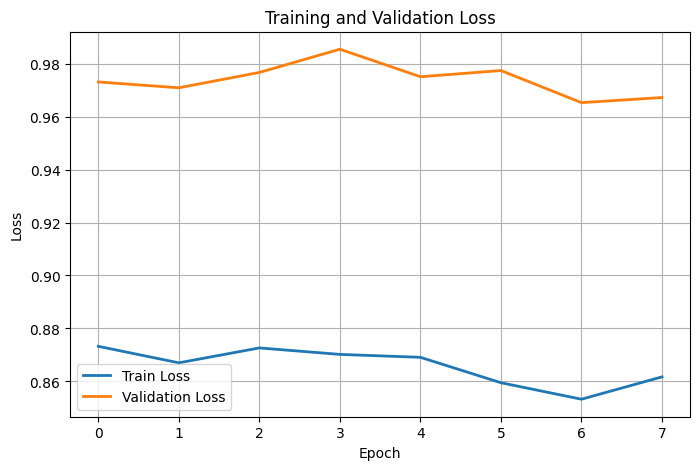

In [24]:
plt.figure(figsize              = (8,5))
plt.plot(train_loss_list, label = 'Train Loss', linewidth=2)
plt.plot(val_loss_list, label   = 'Validation Loss', linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.grid(True)
plt.legend()

plt.show()

### === Train Accuracy & Validation Accuracy ===

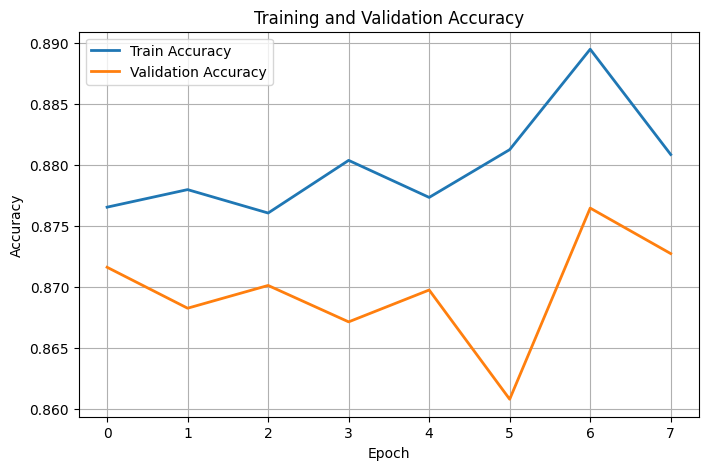

In [25]:
plt.figure(figsize             = (8,5))

plt.plot(train_acc_list, label = 'Train Accuracy', linewidth=2)
plt.plot(val_acc_list, label   = 'Validation Accuracy', linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.grid(True)
plt.legend()

plt.show()

### === CONFUSION MATRIX ===

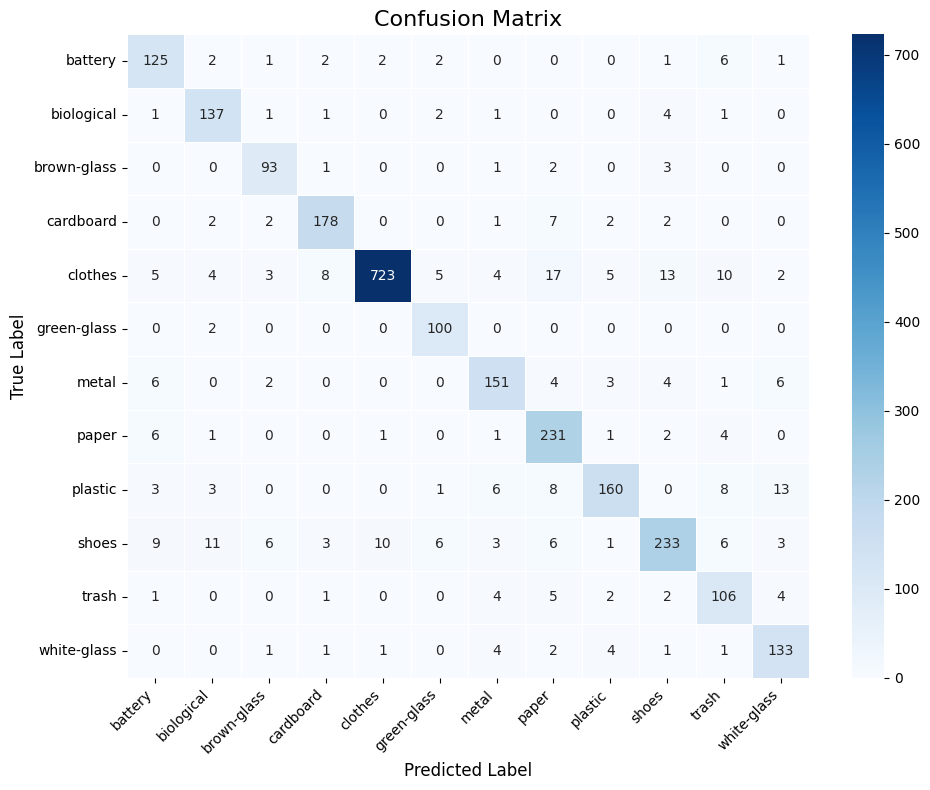

In [31]:
model.eval()

y_true               = []
y_pred               = []

with torch.no_grad():
    for images, labels in test_loader:
        images       = images.to(device)
        labels       = labels.to(device)

        outputs      = model(images)
        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# Confusion Matrix
classes              = train_dataset.classes
cm                   = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))
sns.heatmap(
    cm,
    annot            = True,
    fmt              = "d",
    cmap             = "Blues",
    xticklabels      = classes,
    yticklabels      = classes,
    linewidths       = 0.5
)

plt.title("Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.xticks(rotation  = 45, ha = "right")
plt.yticks(rotation  = 0)
plt.tight_layout()
plt.show()

### === Classification Report ===

In [33]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names = train_dataset.classes,
    digits       = 4
))

              precision    recall  f1-score   support

     battery     0.8013    0.8803    0.8389       142
  biological     0.8457    0.9257    0.8839       148
 brown-glass     0.8532    0.9300    0.8900       100
   cardboard     0.9128    0.9175    0.9152       194
     clothes     0.9810    0.9049    0.9414       799
 green-glass     0.8621    0.9804    0.9174       102
       metal     0.8580    0.8531    0.8555       177
       paper     0.8191    0.9352    0.8733       247
     plastic     0.8989    0.7921    0.8421       202
       shoes     0.8792    0.7845    0.8292       297
       trash     0.7413    0.8480    0.7910       125
 white-glass     0.8210    0.8986    0.8581       148

    accuracy                         0.8840      2681
   macro avg     0.8561    0.8875    0.8697      2681
weighted avg     0.8893    0.8840    0.8846      2681



### === Hiển thị ảnh dự đoán đúng và sai ===

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9306722..2.622571].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9831933..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0665298..1.4440448].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8044444..2.3235295].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0322802..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8458387..2.5877128].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.02868402..2.43084

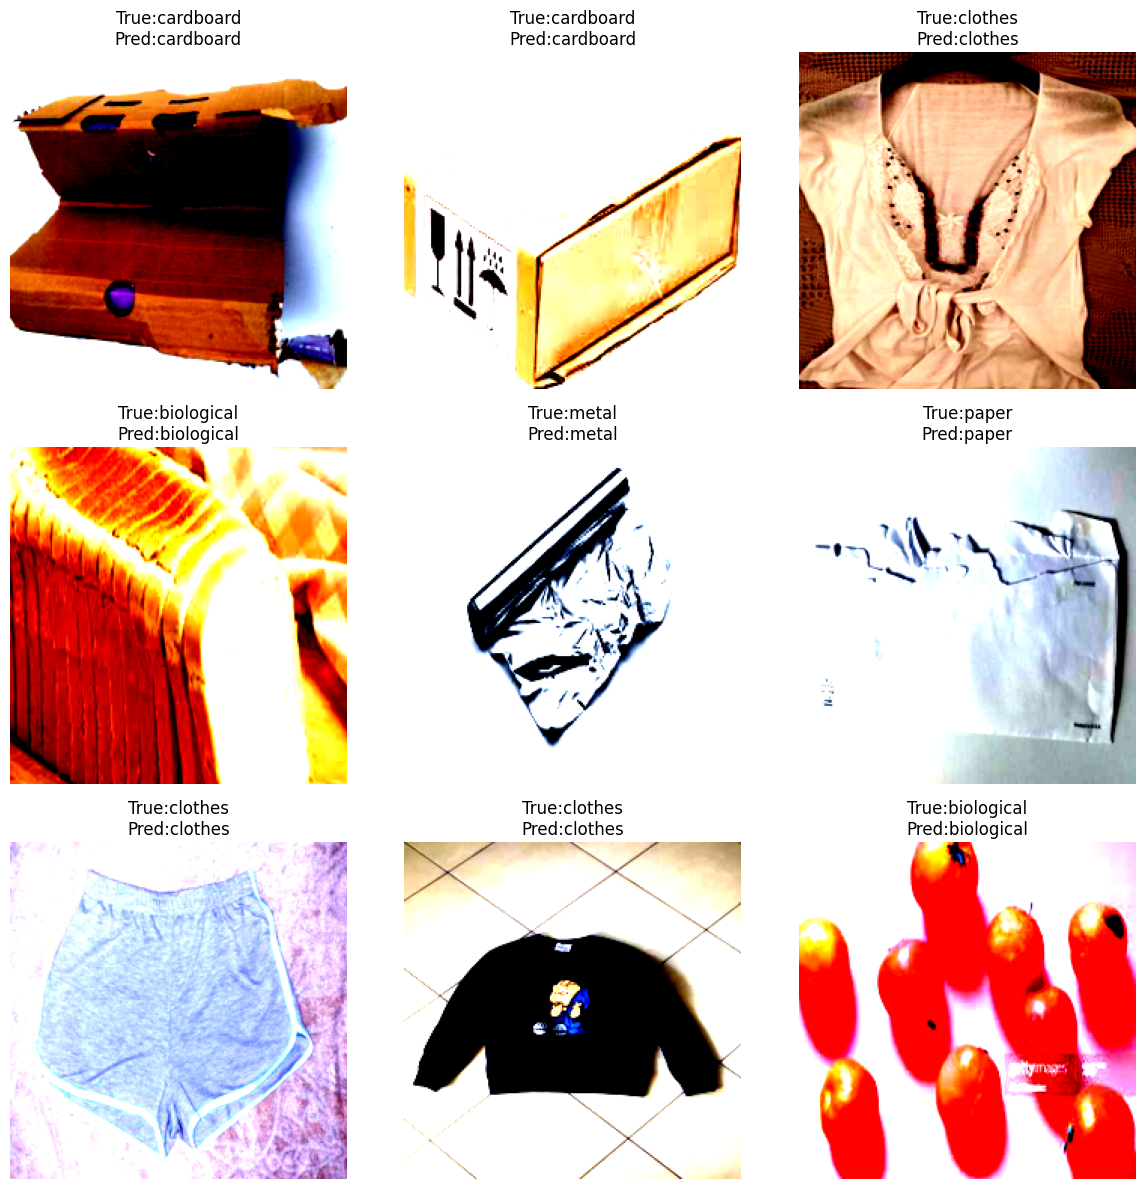

In [34]:
model.eval()

correct_images                     = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs                    = model(images.to(device))
        _, preds                   = torch.max(outputs,1)
        for img,label,pred in zip(images,labels,preds.cpu()):
            if label               == pred:
                correct_images.append((img,label,pred))
            if len(correct_images) == 9:
                break
        if len(correct_images)     == 9:
            break

plt.figure(figsize=(12,12))

for i,(img,label,pred) in enumerate(correct_images):
    plt.subplot(3,3,i+1)
    plt.imshow(img.permute(1,2,0))
    plt.title(f"True:{train_dataset.classes[label]}\nPred:{train_dataset.classes[pred]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### === Ảnh dự đoán sai ===

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2739873].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.2274169..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.5105042..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9980307..2.64].
Clipping input dat

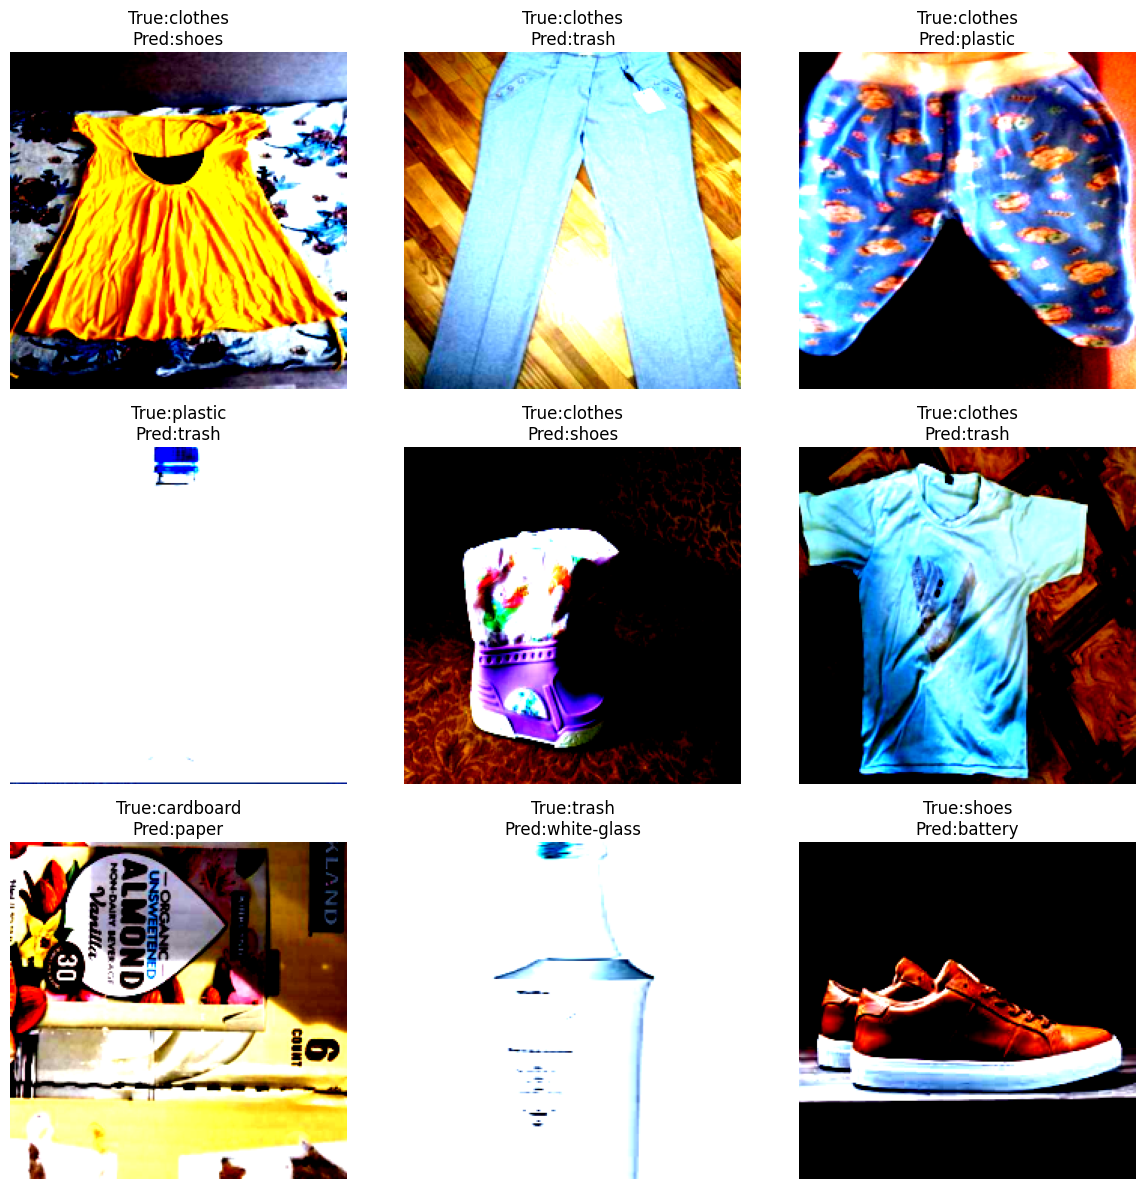

In [35]:
wrong_images                     = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        outputs                  = model(images.to(device))
        _, preds                 = torch.max(outputs,1)
        for img,label,pred in zip(images,labels,preds.cpu()):
            if label             !=pred:
                wrong_images.append((img,label,pred))
            if len(wrong_images) == 9:
                break
        if len(wrong_images)     == 9:
            break
            
plt.figure(figsize               = (12,12))

for i,(img,label,pred) in enumerate(wrong_images):
    plt.subplot(3,3,i+1)
    plt.imshow(img.permute(1,2,0))
    plt.title(f"True:{train_dataset.classes[label]}\nPred:{train_dataset.classes[pred]}")
    plt.axis("off")
    
plt.tight_layout()
plt.show()